<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-12/lab-071a-random-states.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 071a. Random states and typicality

A circuit of many layers with randomly chosen angles prepares a state that has no recognisable structure. To understand how such circuits behave in training, we need to know what a typical state of $N$ qubits looks like. The answer is surprising for anyone used to one or two qubits. In a space of dimension $d=2^N$ almost all states look alike. Every expectation value of a few-qubit observable is close to its average over all states, two random states are nearly orthogonal, and every small group of qubits looks like a set of fair coins. This phenomenon is called concentration of measure, and its quantum form is called typicality.

We first define a uniformly random pure state and sample it on a computer. For one qubit we check that the samples cover the Bloch sphere uniformly and compare them with a sampling that looks uniform and crowds the points at the poles. We then measure, for growing $N$, the distribution of the expectation value $\langle\hat Z_0\rangle$, the overlap of two random states and the distance of a small subsystem from the maximally mixed state, and we compare each with its exact formula. The last computation is the entanglement entropy of a subsystem as a function of its size, the Page curve, which we compare with the ground state of the critical Ising chain. A final paragraph explains why these facts make the gradients of deep random circuits vanish, which Lab 071 (Barren plateaus) then measures. Read this notebook before Lab 071, which builds on it.

Everything is computed exactly with NumPy from sampled state vectors. Sections 1 to 8 form the classroom route and run in well under a minute on a laptop CPU. Section 9 lists exercises for home.

## 1. Double-precision arithmetic

We work in double precision with NumPy and SciPy on the CPU, and Matplotlib draws the figures. No circuits are trained here, so no automatic differentiation is needed. Every random seed is fixed.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"          # no JAX here; kept for consistency with the other notebooks
import json, time
from pathlib import Path
import numpy as np
from scipy.special import betaln
from scipy import stats
import matplotlib.pyplot as plt

TOL = 1e-10
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
NAVY, BLUE, ORANGE, GRAY, GREEN = "#002B5C", "#3E8FD0", "#D35A05", "#5A6270", "#1B7F36"
plt.rcParams.update({"font.size": 13, "axes.labelsize": 13, "xtick.labelsize": 12, "ytick.labelsize": 12,
                     "legend.fontsize": 11, "figure.figsize": (4.8, 3.2), "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight", "pdf.fonttype": 42, "ps.fonttype": 42})
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=200)
def panel(ax, letter):
    ax.text(0.0, 1.03, f"({letter})", transform=ax.transAxes, ha="left", va="bottom")
started = time.perf_counter()
RESULTS = {}

## 2. A uniformly random state

A pure state of $N$ qubits is a unit vector of $d=2^N$ complex amplitudes, defined up to a global phase. A uniformly random state is one drawn so that no direction in this space is preferred. Rotating every sampled state by the same unitary $\hat U$ must then leave the distribution unchanged, since a unitary only changes the basis in which we write the state. The unique distribution of unit vectors with this invariance is called the Haar distribution, after the uniform (Haar) measure on the group of unitaries, and its samples are called Haar-random states.

Sampling is easy. We draw $d$ complex numbers $z_j=x_j+iy_j$, where all $x_j$ and $y_j$ are independent normal random numbers with mean zero and variance one, and normalise,
$$|\psi\rangle=\frac{\sum_{j=0}^{d-1}z_j|j\rangle}{\sqrt{\sum_{j}|z_j|^2}} . \tag{1}$$
The joint density of the $z_j$ is proportional to $e^{-\sum_j|z_j|^2/2}$ and depends only on the length of the vector, which every unitary preserves. The direction of the vector is therefore uniformly distributed [1]. The cell defines the sampler and checks two consequences of the invariance on 20000 states of three qubits. The probability of each bit string averages to $1/d$, and the same holds for the probabilities measured in a rotated basis.

In [2]:
rng = np.random.default_rng(2026)

def haar_states(N, M, rng=rng):
    """M Haar-random pure states of N qubits, equation (1); rows are state vectors."""
    d = 2 ** N
    z = rng.normal(size=(M, d)) + 1j * rng.normal(size=(M, d))
    return z / np.linalg.norm(z, axis=1, keepdims=True)

psi = haar_states(3, 20000)
assert np.allclose(np.linalg.norm(psi, axis=1), 1, atol=TOL)
p = np.abs(psi) ** 2
U = np.linalg.qr(rng.normal(size=(8, 8)) + 1j * rng.normal(size=(8, 8)))[0]      # a fixed random basis change
pU = np.abs(psi @ U.T) ** 2
se = p.std(0).max() / np.sqrt(len(p))                                          # standard error of each mean
print("mean bit-string probabilities:        ", np.round(p.mean(0), 4))
print("mean probabilities in a rotated basis:", np.round(pU.mean(0), 4), "  1/d =", 1 / 8)
assert np.all(np.abs(p.mean(0) - 1 / 8) < 5 * se) and np.all(np.abs(pU.mean(0) - 1 / 8) < 5 * se)

mean bit-string probabilities:         [0.1259 0.1237 0.1264 0.1241 0.1246 0.1246 0.1254 0.1253]
mean probabilities in a rotated basis: [0.1256 0.1247 0.125  0.1252 0.1255 0.1237 0.1263 0.1241]   1/d = 0.125


## 3. One qubit, uniform on the Bloch sphere

For one qubit, a pure state $|\psi\rangle=\cos(\vartheta/2)|0\rangle+e^{i\varphi}\sin(\vartheta/2)|1\rangle$ is a point on the Bloch sphere with the Bloch vector $(\langle\hat X\rangle,\langle\hat Y\rangle,\langle\hat Z\rangle)=(\sin\vartheta\cos\varphi,\sin\vartheta\sin\varphi,\cos\vartheta)$. The one-qubit unitaries act on the Bloch sphere as rotations, so a Haar-random qubit is a point distributed uniformly over the surface of the sphere, with equal numbers of points on equal areas. The area element is $\sin\vartheta\,d\vartheta\,d\varphi=d(\cos\vartheta)\,d\varphi$, so uniformity on the sphere means that $\varphi$ and $z=\cos\vartheta=\langle\hat Z\rangle$ are uniform, the latter on $[-1,1]$.

A tempting shortcut draws $\vartheta$ uniformly from $[0,\pi]$ and $\varphi$ uniformly from $[0,2\pi)$. It treats the thin caps near the poles like the wide belt at the equator and puts as many points into a cap as into a belt of the same height in $\vartheta$, so the points crowd at the poles. The density of $z$ is then $1/(\pi\sqrt{1-z^2})$, which diverges at $z=\pm1$. The cell compares both samplings on 3000 points each and checks the second moment, $\overline{z^2}=1/3$ for the uniform sphere and $1/2$ for the shortcut.

mean of z^2: Haar 0.342 (exact 1/3), uniform in angles 0.493 (exact 1/2)
Kolmogorov-Smirnov test of uniform z for the Haar samples: p-value 0.29


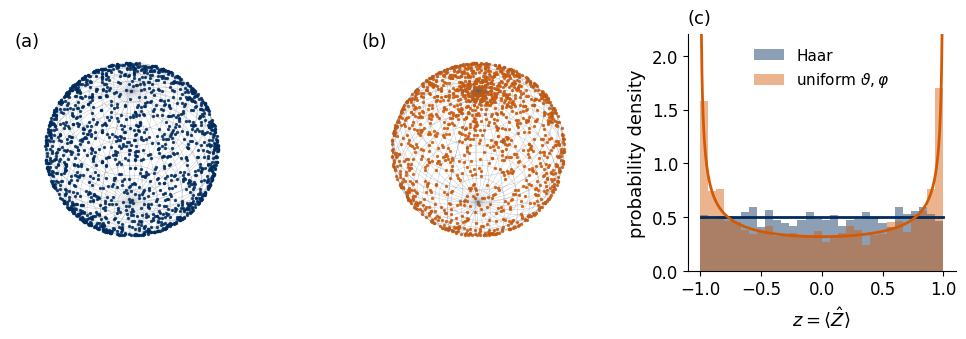

In [3]:
M1 = 3000
def bloch(psi):
    a, b = psi[:, 0], psi[:, 1]
    return np.column_stack([2 * np.real(np.conj(a) * b), 2 * np.imag(np.conj(a) * b), np.abs(a) ** 2 - np.abs(b) ** 2])

r_haar = bloch(haar_states(1, M1))
th, ph = rng.uniform(0, np.pi, M1), rng.uniform(0, 2 * np.pi, M1)
r_wrong = np.column_stack([np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)])
assert np.allclose(np.linalg.norm(r_haar, axis=1), 1, atol=TOL)              # pure states lie on the sphere
z2_haar, z2_wrong = np.mean(r_haar[:, 2] ** 2), np.mean(r_wrong[:, 2] ** 2)
print(f"mean of z^2: Haar {z2_haar:.3f} (exact 1/3), uniform in angles {z2_wrong:.3f} (exact 1/2)")
assert abs(z2_haar - 1 / 3) < 0.03 and abs(z2_wrong - 1 / 2) < 0.03
ks = stats.kstest(r_haar[:, 2], stats.uniform(-1, 2).cdf).pvalue
print(f"Kolmogorov-Smirnov test of uniform z for the Haar samples: p-value {ks:.2f}")
RESULTS["bloch"] = dict(z2_haar=z2_haar, z2_wrong=z2_wrong, ks_pvalue=ks)

fig = plt.figure(figsize=(10.0, 3.6))
u, v = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
for i, (r, c, letter) in enumerate(((r_haar, NAVY, "a"), (r_wrong, ORANGE, "b"))):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")
    ax.plot_wireframe(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v), color=GRAY, lw=0.3, alpha=0.4)
    elev, azim = np.radians(50), np.radians(20)
    front = r @ np.array([np.cos(elev) * np.cos(azim), np.cos(elev) * np.sin(azim), np.sin(elev)]) > 0   # visible half
    ax.scatter(*r[front].T, s=2, color=c, alpha=0.8, depthshade=False)
    ax.set_box_aspect((1, 1, 1), zoom=1.4); ax.set_axis_off(); ax.view_init(elev=50, azim=20)
    ax.text2D(0.02, 0.95, f"({letter})", transform=ax.transAxes)
ax = fig.add_subplot(1, 3, 3)
bins = np.linspace(-1, 1, 31)
ax.hist(r_haar[:, 2], bins=bins, density=True, color=NAVY, alpha=0.45, label="Haar")
ax.hist(r_wrong[:, 2], bins=bins, density=True, color=ORANGE, alpha=0.45, label=r"uniform $\vartheta,\varphi$")
zz = np.linspace(-0.995, 0.995, 400)
ax.plot(zz, 0.5 + 0 * zz, color=NAVY, lw=2); ax.plot(zz, 1 / (np.pi * np.sqrt(1 - zz ** 2)), color=ORANGE, lw=2)
ax.set_xlabel(r"$z=\langle\hat Z\rangle$"); ax.set_ylabel("probability density"); ax.set_ylim(0, 2.2)
ax.legend(frameon=False, loc="upper center"); panel(ax, "c")
fig.tight_layout(); save(fig, "fig_lab071a_bloch"); plt.show()

Panel (a) shows the Haar samples on the visible half of the Bloch sphere, seen from above the northern hemisphere, panel (b) the samples of the shortcut and panel (c) the histograms of $z=\langle\hat Z\rangle$ with the exact densities as lines. The Haar points cover the sphere evenly and their $z$ is flat, whereas the shortcut leaves the equator sparse and piles points up at the poles. A wrong sampler can therefore look plausible in a list of angles and still be far from uniform.

## 4. Concentration of an expectation value

We now look at one fixed observable in random states of $N$ qubits, the expectation value $\langle\hat Z_0\rangle$ of qubit 0. For a single qubit it is spread uniformly over $[-1,1]$. It equals the total probability $w$ of the bit strings with $b_0=0$ minus that of the strings with $b_0=1$, so $\langle\hat Z_0\rangle=2w-1$. In a Haar-random state the weights $|z_j|^2$ in equation (1) are independent exponential random numbers, and the fraction $w$ that falls into one half of the $d$ basis states follows the Beta distribution with both parameters equal to $d/2$. Changing the variable to $z=2w-1$ gives the exact density
$$p_N(z)=\frac{(1-z^2)^{d/2-1}}{2^{d-1}\,B(d/2,d/2)} ,\qquad -1\le z\le1 , \tag{2}$$
where $B$ is the Euler Beta function. The density is symmetric, so the mean vanishes, and the variance of the Beta distribution gives
$$\mathrm{Var}\,\langle\hat Z_0\rangle=\frac1{d+1}=\frac1{2^N+1} . \tag{3}$$
The typical size of $\langle\hat Z_0\rangle$ is therefore about $2^{-N/2}$. With twelve qubits almost every state has $|\langle\hat Z_0\rangle|$ below a few percent, so qubit 0 is found in $0$ and in $1$ with nearly equal probabilities. The cell samples 4000 states for $N=2,6,12$, compares the histograms with equation (2) and checks the variance (3) for $N=2,\dots,12$ within its statistical error.

N =  2: sampled variance 1.946e-01, equation (3) 2.000e-01
N =  6: sampled variance 1.510e-02, equation (3) 1.538e-02


N = 12: sampled variance 2.412e-04, equation (3) 2.441e-04


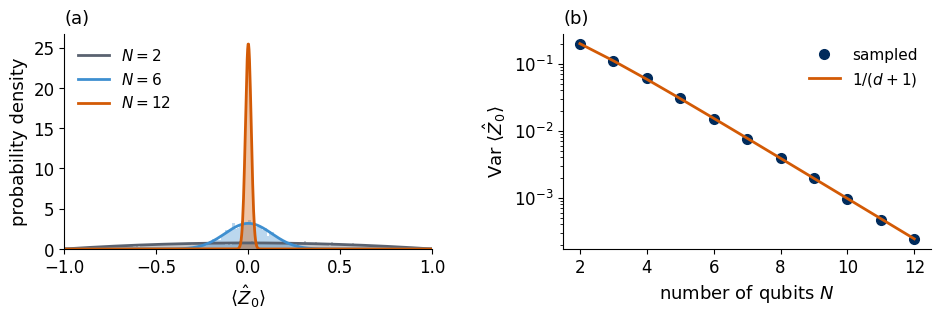

In [4]:
def density_z(z, N):
    a = 2 ** N / 2
    return np.exp((a - 1) * np.log1p(-z ** 2) - (2 * a - 1) * np.log(2) - betaln(a, a))       # equation (2)

def z0_samples(N, M):
    p = np.abs(haar_states(N, M)) ** 2
    return p[:, : 2 ** (N - 1)].sum(1) - p[:, 2 ** (N - 1):].sum(1)            # qubit 0 is the most significant bit

for N in (2, 6, 12):                                                           # equation (2) is a normalised density
    zz = np.linspace(-1, 1, 200001)
    assert abs(np.trapezoid(density_z(zz[1:-1], N), zz[1:-1]) - 1) < 1e-3

M = 4000
NS = np.arange(2, 13)
var = {}
for N in NS:
    z0 = z0_samples(N, M)
    var[N] = z0.var()
    se_var = var[N] * np.sqrt(2 / (M - 1)) * 1.2                               # standard error of a variance (light tails)
    assert abs(var[N] - 1 / (2 ** N + 1)) < 4 * se_var, N                       # equation (3)
    if N in (2, 6, 12):
        print(f"N = {N:2d}: sampled variance {var[N]:.3e}, equation (3) {1 / (2 ** N + 1):.3e}")
RESULTS["var_z0"] = {int(N): float(v) for N, v in var.items()}

fig, axs = plt.subplots(1, 2, figsize=(9.6, 3.4))
rng_plot = np.random.default_rng(12)
for N, c in ((2, GRAY), (6, BLUE), (12, ORANGE)):
    p = np.abs(haar_states(N, M, rng_plot)) ** 2
    z0 = p[:, : 2 ** (N - 1)].sum(1) - p[:, 2 ** (N - 1):].sum(1)
    axs[0].hist(z0, bins=np.linspace(-1, 1, 161), density=True, color=c, alpha=0.35)
    zz = np.linspace(-0.999, 0.999, 800)
    axs[0].plot(zz, density_z(zz, N), color=c, lw=2, label=f"$N={N}$")
axs[0].set_xlabel(r"$\langle\hat Z_0\rangle$"); axs[0].set_ylabel("probability density"); axs[0].set_xlim(-1, 1)
axs[0].legend(frameon=False, loc="upper left")
axs[1].semilogy(NS, [var[N] for N in NS], "o", color=NAVY, ms=7, label="sampled")
axs[1].semilogy(NS, 1 / (2.0 ** NS + 1), "-", color=ORANGE, lw=2, label=r"$1/(d+1)$")
axs[1].set_xlabel("number of qubits $N$"); axs[1].set_ylabel(r"Var $\langle\hat Z_0\rangle$"); axs[1].legend(frameon=False)
for a, letter in zip(axs, "ab"):
    panel(a, letter)
fig.tight_layout(w_pad=2.0); save(fig, "fig_lab071a_concentration"); plt.show()

Panel (a) shows the histograms of $\langle\hat Z_0\rangle$ over 4000 random states with the exact densities (2) as lines, and panel (b) the sampled variance against $N$ on a logarithmic scale together with equation (3). For two qubits the expectation value is spread over the whole interval, while for twelve qubits it is squeezed into a narrow peak at zero. The variance halves with every added qubit.

This is one instance of a general statement, Lévy's lemma [2]. Let $f$ be any real function of the state that changes slowly, $|f(\psi)-f(\phi)|\le\eta\,\||\psi\rangle-|\phi\rangle\|$ with a constant $\eta$. For a Haar-random state the probability that $f$ deviates from its mean by more than $\varepsilon$ obeys
$$\mathrm{Prob}\big(|f(\psi)-\overline f|\ge\varepsilon\big)\le2\exp\!\Big(-C\,\frac{d\,\varepsilon^2}{\eta^2}\Big) , \tag{4}$$
where $C$ is a positive constant independent of $d$. Any expectation value $f=\langle\psi|\hat O|\psi\rangle$ of an observable with eigenvalues in $[-1,1]$ satisfies the condition with $\eta=2$. The probability of a visible deviation falls exponentially in $d=2^N$, that is doubly exponentially in the number of qubits, which is why the peaks in panel (a) narrow so quickly.

## 5. Two random states are almost orthogonal

In three dimensions two random directions have a typical overlap of order one. In $d$ dimensions the overlap of two independent Haar-random states is small. By the invariance of Section 2 we may fix one of them as $|0\dots0\rangle$, and the squared overlap becomes the probability of the bit string $0\dots0$ in the other state, one of $d$ weights that sum to one. Its distribution is a Beta distribution with parameters $1$ and $d-1$, with the mean
$$\overline{|\langle\psi|\phi\rangle|^2}=\frac1d . \tag{5}$$
For large $d$ the rescaled overlap $x=d\,|\langle\psi|\phi\rangle|^2$ follows the exponential density $e^{-x}$, known as the Porter–Thomas distribution of the probabilities of random states [3]. At most $d$ states are mutually orthogonal, whereas the number of states that are pairwise orthogonal up to a fixed small tolerance grows exponentially with $d$. The cell checks equation (5) on 20000 pairs for $N=2,\dots,10$ and draws the distribution of $x$ for $N=8$.

d * mean overlap for N = 2..10: [0.992 0.999 1.004 1.005 1.01  0.997 0.998 1.005 0.997]


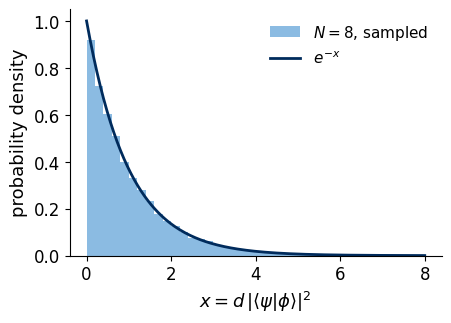

In [5]:
Mp = 20000
ov = {}
for N in range(2, 11):
    a, b = haar_states(N, Mp), haar_states(N, Mp)
    o = np.abs(np.sum(np.conj(a) * b, axis=1)) ** 2
    ov[N] = o
    assert abs(o.mean() * 2 ** N - 1) < 5 * o.std() * 2 ** N / np.sqrt(Mp)        # equation (5)
print("d * mean overlap for N = 2..10:", np.round([ov[N].mean() * 2 ** N for N in range(2, 11)], 3))
RESULTS["overlap_d_times_mean"] = {N: float(ov[N].mean() * 2 ** N) for N in ov}

fig, ax = plt.subplots()
x = ov[8] * 2 ** 8
ax.hist(x, bins=np.linspace(0, 8, 41), density=True, color=BLUE, alpha=0.6, label=r"$N=8$, sampled")
xx = np.linspace(0, 8, 200)
ax.plot(xx, np.exp(-xx), color=NAVY, lw=2, label=r"$e^{-x}$")
ax.set_xlabel(r"$x=d\,|\langle\psi|\phi\rangle|^2$"); ax.set_ylabel("probability density"); ax.legend(frameon=False)
save(fig, "fig_lab071a_overlap"); plt.show()

The histogram of the rescaled overlap for eight qubits follows the exponential density. Most pairs have an overlap below a few times $1/d$, and overlaps of order one essentially never occur. Since every bit-string probability of a random state is such an overlap, all $2^N$ probabilities are of order $2^{-N}$, and a measurement in the computational basis returns a nearly uniform distribution of bit strings.

## 6. A small subsystem looks maximally mixed

We split the register into a subsystem $A$ of the first $n_A$ qubits, with dimension $d_A=2^{n_A}$, and the rest $B$, with $d_B=2^{N-n_A}$. All predictions for measurements on $A$ alone are contained in the reduced density matrix
$$\hat\rho_A=\mathrm{Tr}_B|\psi\rangle\langle\psi| ,\qquad (\rho_A)_{aa'}=\sum_b\psi_{ab}\psi^*_{a'b} , \tag{6}$$
where $\psi_{ab}$ is the state vector reshaped into a $d_A\times d_B$ matrix. The maximally mixed state $\hat I/d_A$ gives every outcome of every measurement on $A$ with the probabilities of fair coins. To measure how close $\hat\rho_A$ comes to it we use the trace distance $T(\hat\rho,\hat\sigma)=\frac12\sum_k|\mu_k|$, where $\mu_k$ are the eigenvalues of $\hat\rho-\hat\sigma$. It is the largest difference between the probabilities that $\hat\rho$ and $\hat\sigma$ assign to the same outcome of any measurement.

The average purity of $\hat\rho_A$ over Haar-random states is known exactly [4],
$$\overline{\mathrm{Tr}\,\hat\rho_A^2}=\frac{d_A+d_B}{d_Ad_B+1} . \tag{7}$$
Since $\mathrm{Tr}(\hat\rho_A-\hat I/d_A)^2=\mathrm{Tr}\,\hat\rho_A^2-1/d_A$ and a sum of $d_A$ absolute values is at most $\sqrt{d_A}$ times the square root of the sum of their squares, the average trace distance is bounded by
$$\overline{T\big(\hat\rho_A,\hat I/d_A\big)}\le\frac12\sqrt{\frac{d_A^2-1}{d_Ad_B+1}}\approx\frac12\sqrt{\frac{d_A}{d_B}} . \tag{8}$$
A subsystem much smaller than the rest is therefore almost maximally mixed in almost every state of the whole register [5]. The cell samples 300 states for $N=2,\dots,14$, checks equation (7) and the bound (8) for $n_A=1$ and $n_A=2$, and plots the average trace distance.

mean trace distance, n_A = 1, N = 2, 6, 10, 14: [0.3648 0.0988 0.0248 0.0058]


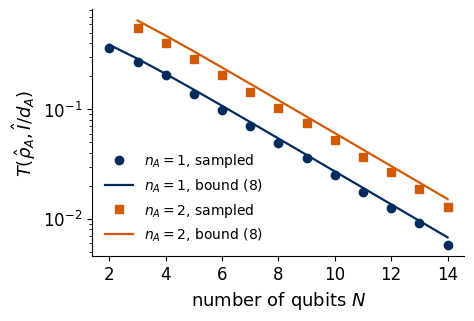

In [6]:
def reduced(psi, nA, N):
    m = psi.reshape(2 ** nA, 2 ** (N - nA))
    return m @ m.conj().T                                                     # equation (6)

def trace_distance(r, s):
    return 0.5 * np.abs(np.linalg.eigvalsh(r - s)).sum()

Mt, NT = 300, np.arange(2, 15)
TD = {1: [], 2: []}
for N in NT:
    states = haar_states(N, Mt)
    for nA in (1, 2):
        if nA >= N:
            TD[nA].append(np.nan); continue
        dA, dB = 2 ** nA, 2 ** (N - nA)
        rhos = [reduced(s, nA, N) for s in states]
        pur = np.array([np.real(np.trace(r @ r)) for r in rhos])
        assert abs(pur.mean() - (dA + dB) / (dA * dB + 1)) < 5 * pur.std() / np.sqrt(Mt) + TOL     # equation (7)
        td = np.mean([trace_distance(r, np.eye(dA) / dA) for r in rhos])
        assert td <= 0.5 * np.sqrt((dA ** 2 - 1) / (dA * dB + 1)) + TOL                        # bound (8)
        TD[nA].append(td)
TD = {k: np.array(v) for k, v in TD.items()}
print("mean trace distance, n_A = 1, N = 2, 6, 10, 14:", np.round(TD[1][[0, 4, 8, 12]], 4))
RESULTS["trace_distance"] = {k: dict(zip(NT.tolist(), v.tolist())) for k, v in TD.items()}

fig, ax = plt.subplots()
for nA, c, mk in ((1, NAVY, "o"), (2, ORANGE, "s")):
    ok = ~np.isnan(TD[nA])
    dA, dB = 2 ** nA, 2.0 ** (NT[ok] - nA)
    ax.semilogy(NT[ok], TD[nA][ok], mk, color=c, ms=6, label=f"$n_A={nA}$, sampled")
    ax.semilogy(NT[ok], 0.5 * np.sqrt((dA ** 2 - 1) / (dA * dB + 1)), "-", color=c, lw=1.6, label=f"$n_A={nA}$, bound (8)")
ax.set_xlabel("number of qubits $N$"); ax.set_ylabel(r"$T(\hat\rho_A,\hat I/d_A)$")
ax.legend(frameon=False, fontsize=10, loc="lower left")
save(fig, "fig_lab071a_subsystem"); plt.show()

The figure shows the average trace distance between $\hat\rho_A$ and the maximally mixed state for one and two qubits in $A$, on a logarithmic scale, with the bound (8) as lines. The distance falls by a factor of about $\sqrt2$ per added qubit and stays just below the bound. With fourteen qubits the outcome probabilities of any measurement on one or two of them differ from those of fair coins by less than one percent in a typical state of the whole register. The information of a random state sits in correlations among many qubits, invisible to measurements on a few.

## 7. The Page curve

The entanglement between $A$ and $B$ in a pure state is measured by the von Neumann entropy of $\hat\rho_A$ in bits,
$$S(\hat\rho_A)=-\sum_k\lambda_k\log_2\lambda_k , \tag{9}$$
where $\lambda_k$ are the eigenvalues of $\hat\rho_A$, equal to the squared Schmidt coefficients of the cut. It can never exceed $\min(n_A,N-n_A)$, the number of qubits of the smaller part. Section 6 suggests that a random state comes close to this maximum. The exact average over Haar-random states was conjectured by Page [6] and later proved, and for $d_A\le d_B$ it reads
$$\overline{S(\hat\rho_A)}=\frac{1}{\ln2}\Bigg(\sum_{k=d_B+1}^{d_Ad_B}\frac1k-\frac{d_A-1}{2d_B}\Bigg)\approx n_A-\frac{d_A}{2d_B\ln2} . \tag{10}$$
As a function of $n_A$ the average entropy rises by almost one bit per qubit up to the middle of the chain and falls symmetrically afterwards. This is the Page curve, and its linear growth with the size of the subsystem is called a volume law.

Ground states of local Hamiltonians behave differently. Their entanglement comes from the bonds that cross the cut, so for a gapped chain it saturates at a constant as $n_A$ grows (an area law), and at a critical point it grows only logarithmically [7, 8]. We compare 40 Haar-random states of $N=10$ qubits with the ground state of the critical transverse-field Ising chain $\hat{\mathcal H}=-J\sum_{i=0}^{N-2}\hat Z_i\hat Z_{i+1}-h\sum_{i=0}^{N-1}\hat X_i$ at $h=J=1$.

n_A = 5: Page 4.279 bits, sampled 4.278 +- 0.021, critical Ising ground state 0.547 bits


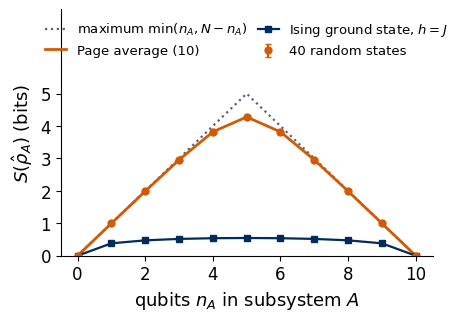

In [7]:
def entropy_bits(psi, nA, N):
    s = np.linalg.svd(psi.reshape(2 ** nA, 2 ** (N - nA)), compute_uv=False) ** 2
    s = s[s > 1e-14]
    return float(-(s * np.log2(s)).sum())                                     # equation (9)

def page_bits(nA, N):
    dA, dB = 2 ** min(nA, N - nA), 2 ** max(nA, N - nA)
    k = np.arange(dB + 1, dA * dB + 1)
    return ((1.0 / k).sum() - (dA - 1) / (2 * dB)) / np.log(2)                 # equation (10)

N = 10
X = np.array([[0, 1], [1, 0]]); Z = np.diag([1.0, -1.0]); I2 = np.eye(2)
def op(single, i):
    out = np.array([[1.0]])
    for q in range(N):
        out = np.kron(out, single if q == i else I2)
    return out
H_ising = sum(-op(Z, i) @ op(Z, i + 1) for i in range(N - 1)) + sum(-op(X, i) for i in range(N))
gs = np.linalg.eigh(H_ising)[1][:, 0]

nAs = np.arange(0, N + 1)
haar10 = haar_states(N, 40)
S_haar = np.array([[entropy_bits(h, n, N) for n in nAs] for h in haar10])
S_gs = np.array([entropy_bits(gs, n, N) for n in nAs])
S_page = np.array([page_bits(n, N) for n in nAs])
assert abs(page_bits(1, 2) - (1 / 3 + 1 / 4 - 1 / 4) / np.log(2)) < TOL        # N = 2: (1/3 + 1/4 - 1/4)/ln 2
for n in nAs[1:-1]:                                                            # sampled means agree with equation (10)
    assert abs(S_haar[:, n].mean() - S_page[n]) < 5 * S_haar[:, n].std() / np.sqrt(40) + 1e-3
lam = np.linalg.eigvalsh(reduced(haar10[0], 3, N)); lam = lam[lam > 1e-14]
assert abs(-(lam * np.log2(lam)).sum() - S_haar[0, 3]) < 1e-8                # eigenvalues of (6) = squared Schmidt coefficients
print(f"n_A = 5: Page {S_page[5]:.3f} bits, sampled {S_haar[:, 5].mean():.3f} +- {S_haar[:, 5].std():.3f}, "
      f"critical Ising ground state {S_gs[5]:.3f} bits")
RESULTS["page"] = dict(N=N, page=S_page.tolist(), haar_mean=S_haar.mean(0).tolist(), haar_std=S_haar.std(0).tolist(),
                       ising=S_gs.tolist())

fig, ax = plt.subplots()
ax.plot(nAs, np.minimum(nAs, N - nAs), ls=":", color=GRAY, lw=1.6, label=r"maximum $\min(n_A,N-n_A)$")
ax.plot(nAs, S_page, color=ORANGE, lw=2, label="Page average (10)")
ax.errorbar(nAs, S_haar.mean(0), yerr=S_haar.std(0), fmt="o", color=ORANGE, ms=5, capsize=2, label="40 random states")
ax.plot(nAs, S_gs, "s-", color=NAVY, ms=5, lw=1.6, label="Ising ground state, $h=J$")
ax.set_xlabel(r"qubits $n_A$ in subsystem $A$"); ax.set_ylabel(r"$S(\hat\rho_A)$ (bits)")
ax.set_xticks(range(0, N + 1, 2)); ax.set_ylim(0, 7.6); ax.set_yticks(range(0, 6))
ax.legend(frameon=False, loc="upper center", ncol=2, fontsize=9.5, columnspacing=0.8, handlelength=1.6)
save(fig, "fig_lab071a_page_curve"); plt.show()

The random states lie on the Page curve, a tent just below the dotted maximum, and their spread is too small to see at this scale. At the middle cut they carry about 4.3 bits of entanglement, close to three quarters of a bit below the maximum of five, in agreement with equation (10). The critical Ising ground state stays below one bit at every cut and grows only slowly towards the middle. A ground state of a local Hamiltonian is thus an exceptional, weakly entangled state, and a randomly chosen state is a poor guess for it.

## 8. From typicality to vanishing gradients

A variational circuit with many layers and random initial angles produces states whose averages of expectation values and of their squares are, to a good approximation, those of Haar-random states [9]. The cost of such a circuit, an expectation value $\langle\hat O\rangle$, then concentrates around its average as in equation (3), with fluctuations of order $2^{-N/2}$. By the parameter-shift rule the derivative of the cost with respect to one angle is the difference of two such expectation values at shifted angles, so it concentrates around zero as well and its variance decays exponentially with $N$. The training landscape seen from a random start is then flat almost everywhere, and on a device the gradient has to be resolved against shot noise with a number of shots that grows exponentially with $N$. This barren plateau is the subject of the next notebook, Lab 071 (Barren plateaus), which measures the variance of gradients for two circuit families and three cost functions.

## 9. Exercises

1. Sample one-qubit states as $\hat R_z(\varphi)\hat R_y(\vartheta)|0\rangle$ with $\varphi$ uniform in $[0,2\pi)$ and $\vartheta=\arccos(1-2u)$, where $u$ is uniform in $[0,1]$. Show with the histogram of $z$ and with $\overline{z^2}$ that these states are Haar-random, and explain the choice of $\vartheta$ with the area element of Section 3.
2. Repeat Section 4 for the two-qubit observable $\hat Z_0\hat Z_1$ and for the projector $|0\dots0\rangle\langle0\dots0|$. Check that the variance of $\langle\hat Z_0\hat Z_1\rangle$ is again $1/(d+1)$ and explain why the projector has a variance of order $1/d^2$.
3. Compute the bound (8) for $n_A=N/2$ and show that it no longer guarantees a small distance. Compare with the sampled trace distance for $N=8$.
4. Plot the half-chain entropy of the Ising ground state for $N=10$ against the field $h\in[0,2]$, and compare its largest value with the Page value at the middle cut.
5. Draw 2000 states with real Gaussian amplitudes instead of complex ones and compare the variance of $\langle\hat Z_0\rangle$ with equation (3). Real random states have the variance $2/(d+2)$.

## 10. Summary

A uniformly random pure state is drawn by normalising a vector of independent complex Gaussian amplitudes, which gives a distribution that no unitary can change. For one qubit this is the uniform distribution on the Bloch sphere, whereas angles drawn uniformly crowd the points at the poles. In many qubits random states concentrate. The expectation value of a single-qubit observable has variance $1/(2^N+1)$, Lévy's lemma bounds the probability of any visible deviation by an exponential in the dimension, two random states are nearly orthogonal with squared overlap $1/2^N$ on average, and a few qubits of a random state are almost maximally mixed. The entanglement entropy of a subsystem follows the Page curve, close to the largest possible value, while the ground state of the critical Ising chain carries far less entanglement. The concentration of expectation values in random states is the origin of the vanishing gradients of deep random circuits. All numbers were computed from exact state vectors sampled on a classical computer.

## References

[1] F. Mezzadri, How to generate random matrices from the classical compact groups, Notices Am. Math. Soc. **54**, 592 (2007), [arXiv:math-ph/0609050](https://arxiv.org/abs/math-ph/0609050).

[2] P. Hayden, D. W. Leung, and A. Winter, Aspects of generic entanglement, Commun. Math. Phys. **265**, 95 (2006), [doi:10.1007/s00220-006-1535-6](https://doi.org/10.1007/s00220-006-1535-6).

[3] C. E. Porter and R. G. Thomas, Fluctuations of nuclear reaction widths, Phys. Rev. **104**, 483 (1956), [doi:10.1103/PhysRev.104.483](https://doi.org/10.1103/PhysRev.104.483).

[4] E. Lubkin, Entropy of an n-system from its correlation with a k-reservoir, J. Math. Phys. **19**, 1028 (1978), [doi:10.1063/1.523763](https://doi.org/10.1063/1.523763).

[5] S. Popescu, A. J. Short, and A. Winter, Entanglement and the foundations of statistical mechanics, Nat. Phys. **2**, 754 (2006), [doi:10.1038/nphys444](https://doi.org/10.1038/nphys444).

[6] D. N. Page, Average entropy of a subsystem, Phys. Rev. Lett. **71**, 1291 (1993), [doi:10.1103/PhysRevLett.71.1291](https://doi.org/10.1103/PhysRevLett.71.1291).

[7] J. Eisert, M. Cramer, and M. B. Plenio, Colloquium: Area laws for the entanglement entropy, Rev. Mod. Phys. **82**, 277 (2010), [doi:10.1103/RevModPhys.82.277](https://doi.org/10.1103/RevModPhys.82.277).

[8] P. Calabrese and J. Cardy, Entanglement entropy and quantum field theory, J. Stat. Mech. (2004) P06002, [doi:10.1088/1742-5468/2004/06/P06002](https://doi.org/10.1088/1742-5468/2004/06/P06002).

[9] J. R. McClean, S. Boixo, V. N. Smelyanskiy, R. Babbush, and H. Neven, Barren plateaus in quantum neural network training landscapes, Nat. Commun. **9**, 4812 (2018), [doi:10.1038/s41467-018-07090-4](https://doi.org/10.1038/s41467-018-07090-4).